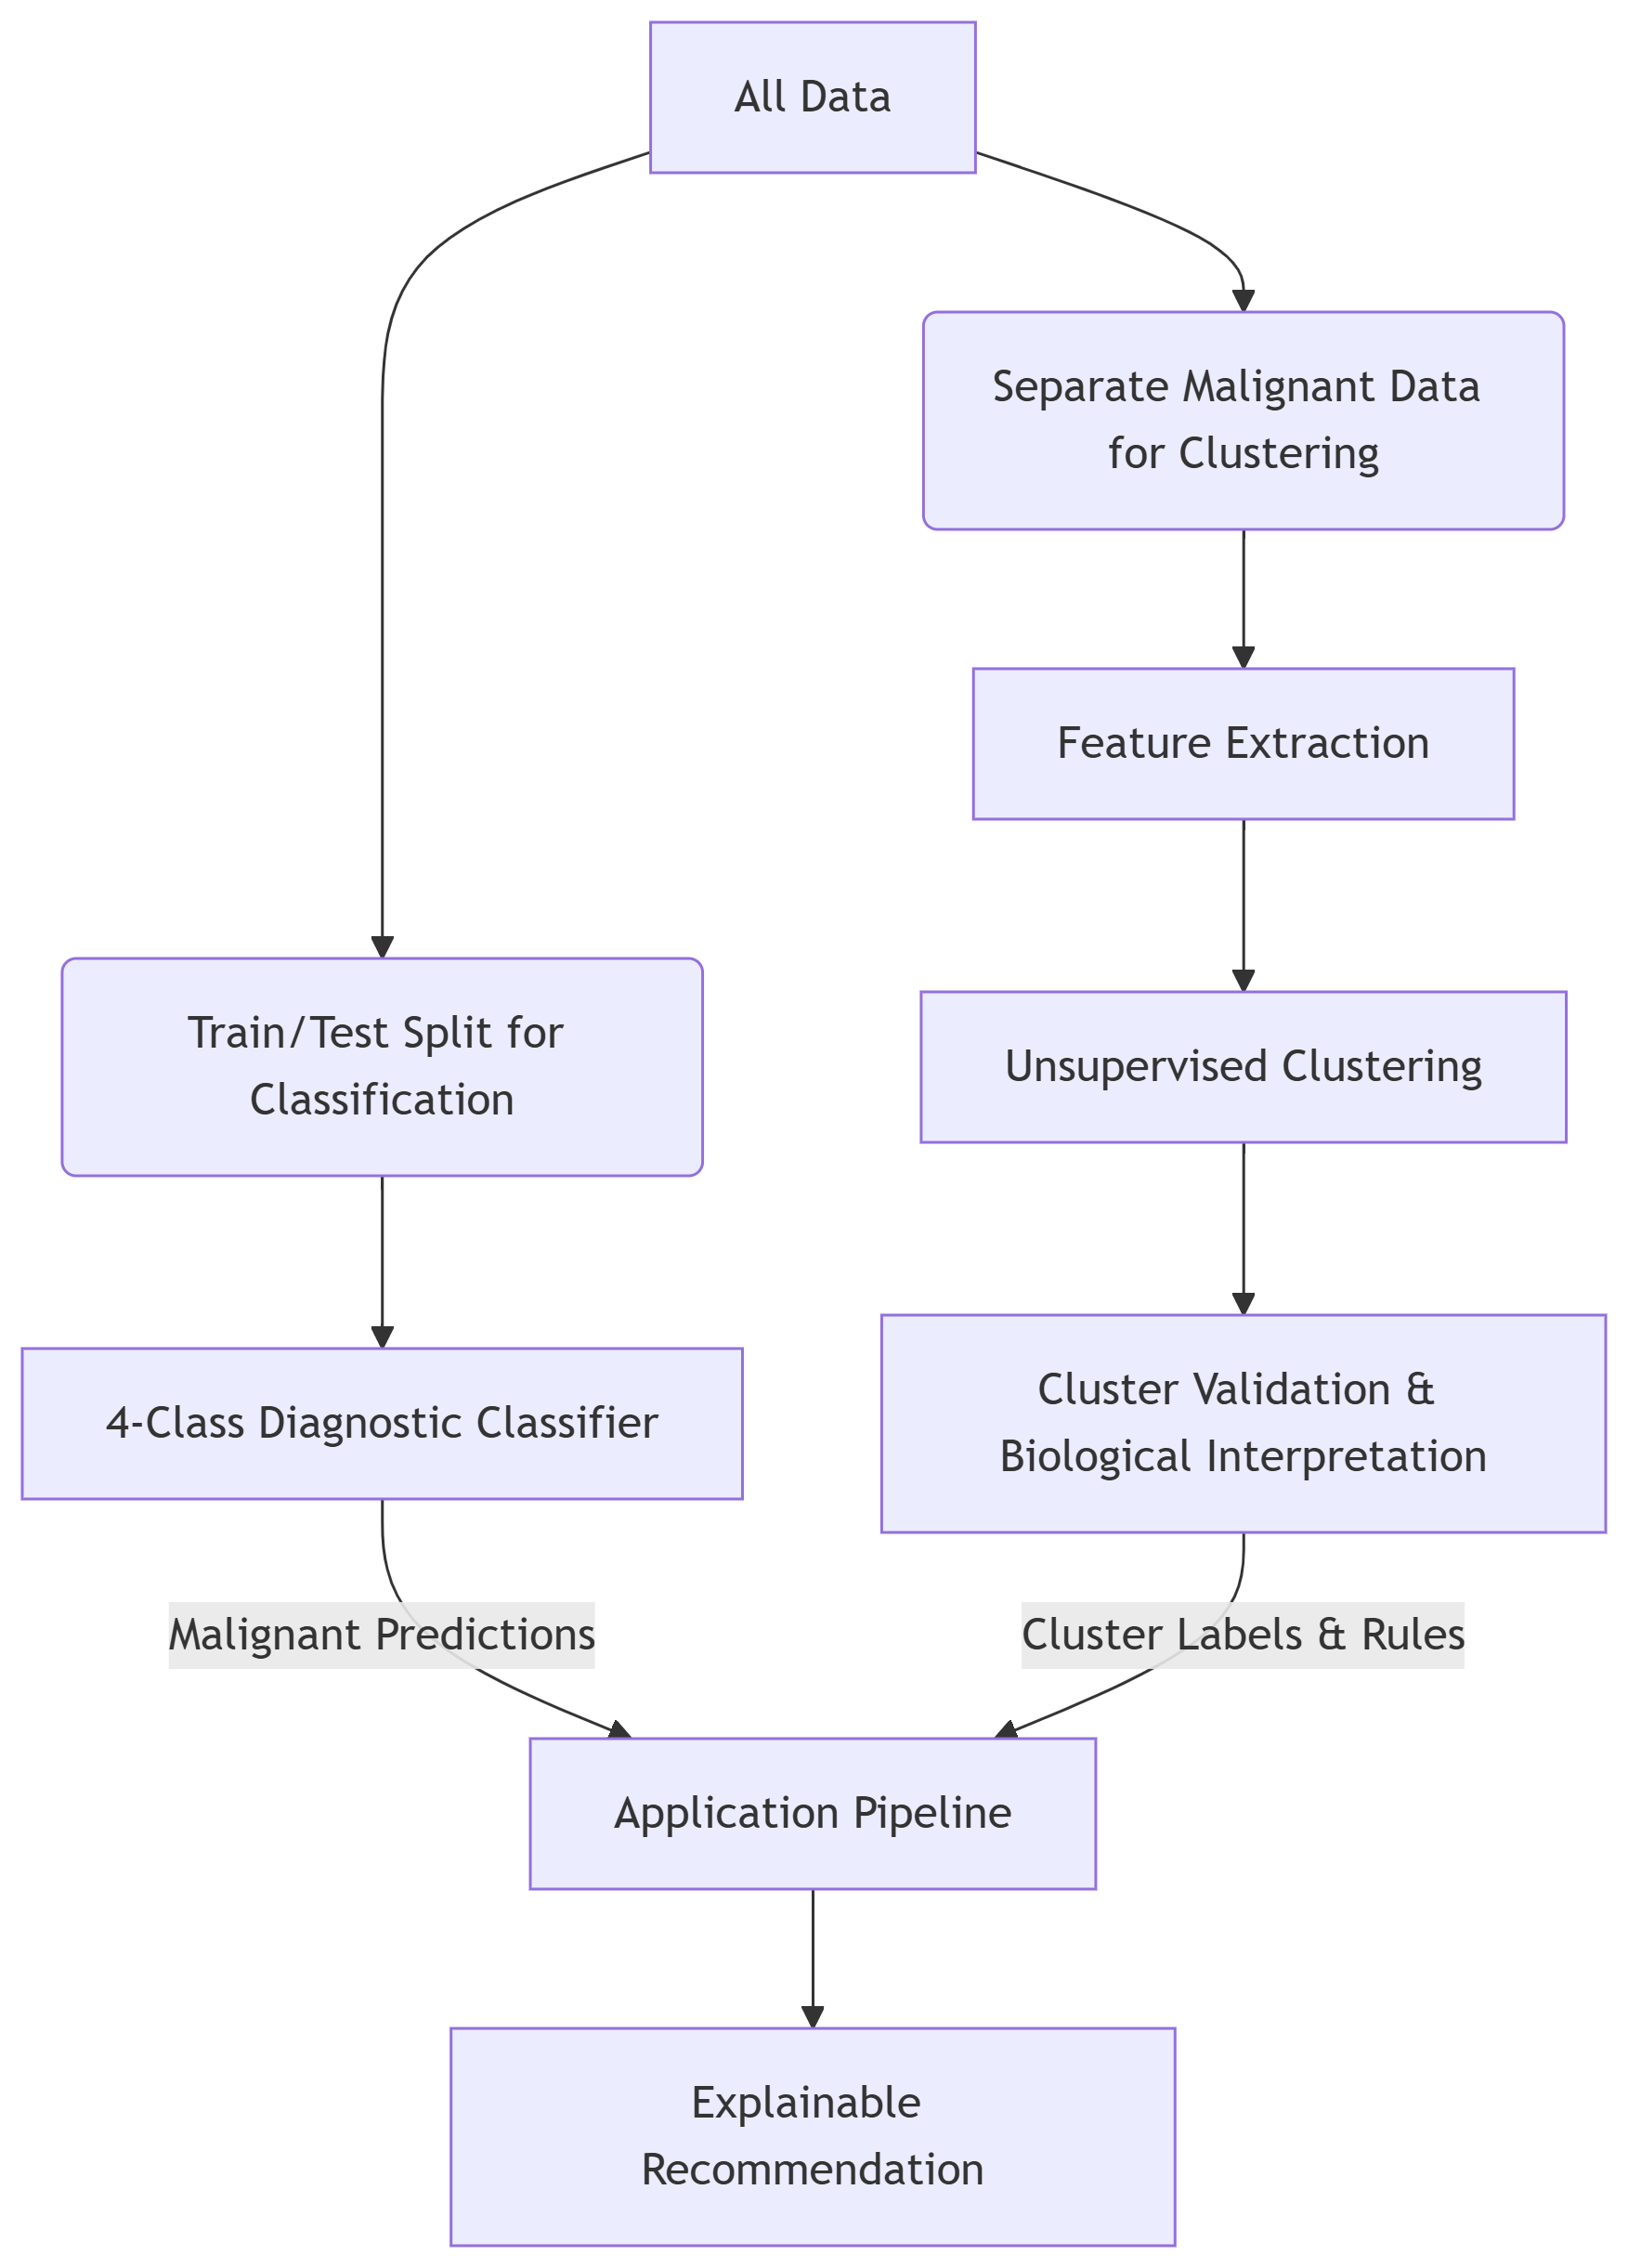

In [ ]:
BreastCancerPhD/
│
├── data/
│   ├── raw/                 # Original BACH images
│   └── processed/           # Processed arrays/labels
│
├── models/                  # Saved models & scalers
│   ├── classifier.h5
│   ├── kmeans.pkl
│   ├── scaler.pkl
│   └── feature_extractor/   # (Optional) Saved ResNet50
│
├── results/
│   ├── figures/             # All plots for thesis
│   └── tables/              # CSV results
│
└── app.py                   # Final Gradio UI

SyntaxError: invalid character '│' (U+2502) (ipython-input-3396817723.py, line 2)

## **Phase 1: Data Preparation & Exploration (Notebook 1)**
Goal: Load data, understand class distribution, split correctly, and generate exploratory figures.

In [ ]:
!pip install opencv-python

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.0/67.0 MB 18.9 MB/s eta 0:00:00


In [ ]:
!pip install tensorflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 620.7/620.7 MB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.5/57.5 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.5/24.5 MB 79.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 106.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 120.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 224.5/224.5 kB 17.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 5.9 MB/s eta 0:00:00


In [ ]:
# --- imports ---
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical

In [ ]:
# --- 1. Set Paths & Parameters ---
DATA_DIR = "/content/drive/MyDrive/BreastCancerProject/Train"
CLASS_MAP = {'Normal': 0, 'Benign': 1, 'InSitu': 2, 'Invasive': 3}
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42
np.random.seed(SEED)

In [ ]:
# --- 2. Data Loading Function ---
def load_data(base_dir, class_map):
    """
    Loads images and labels from class subfolders.
    Returns a dictionary for clarity and to avoid tuple confusion.
    """
    data = {'images': [], 'labels': [], 'filenames': []}
    for class_name, label in class_map.items():
        class_dir = os.path.join(base_dir, class_name)
        for filename in os.listdir(class_dir):
            if filename.endswith('.tif'):
                img_path = os.path.join(class_dir, filename)
                img = cv2.imread(img_path)
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB) # Convert to RGB
                img = cv2.resize(img, IMG_SIZE)
                data['images'].append(img)
                data['labels'].append(label)
                data['filenames'].append(f"{class_name}/{filename}")
    # Convert lists to numpy arrays
    data['images'] = np.array(data['images'])
    data['labels'] = np.array(data['labels'])
    return data

print("Loading data...")
all_data = load_data(DATA_DIR, CLASS_MAP)
print(f"Data loaded successfully! Shape: {all_data['images'].shape}")

Loading data...
Data loaded successfully! Shape: (400, 224, 224, 3)


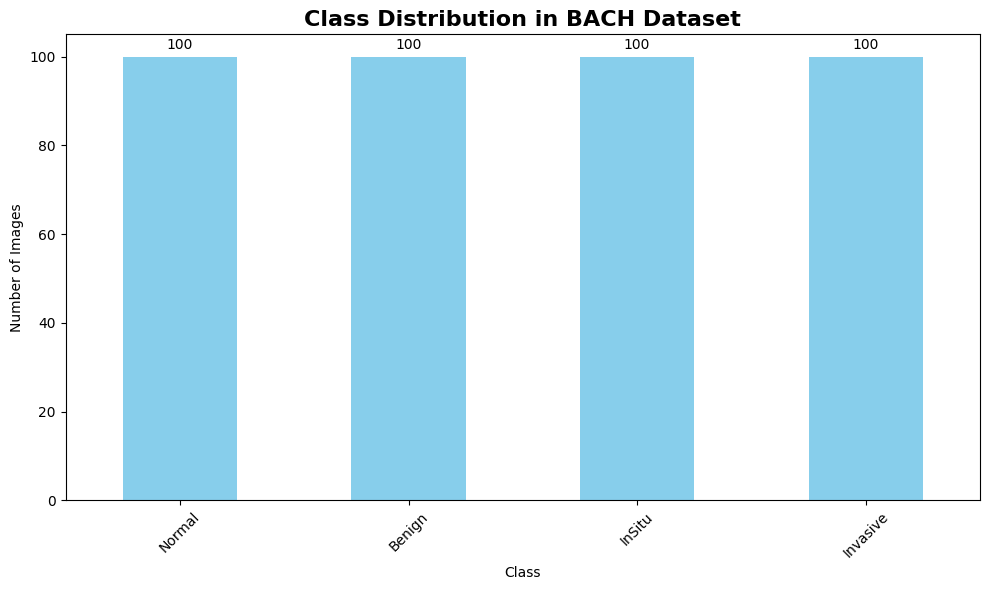

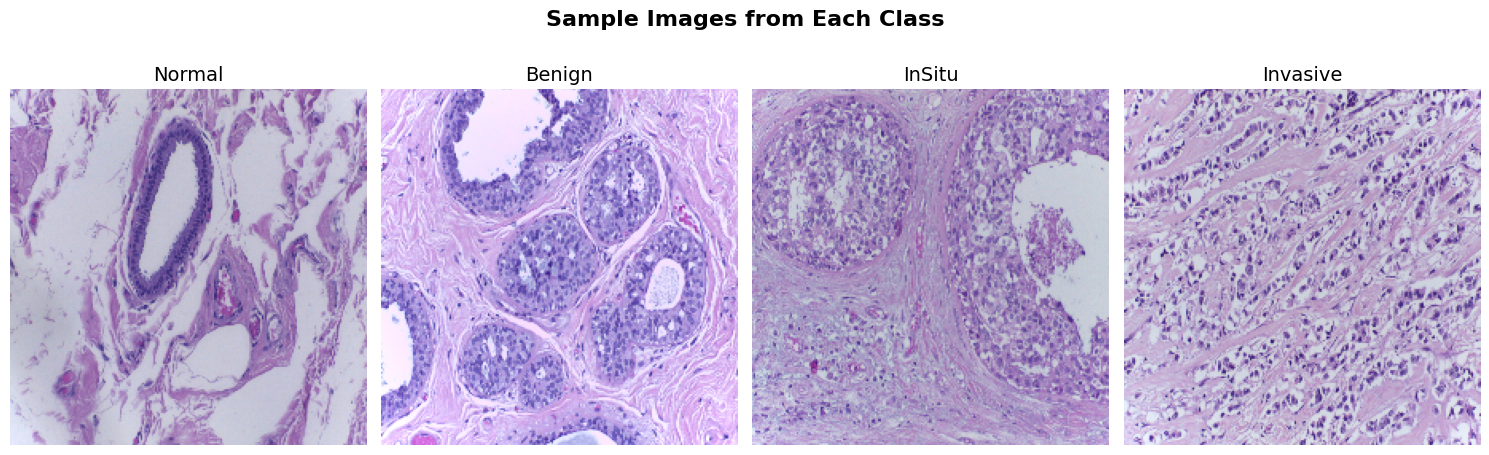

In [ ]:
# --- 3. Exploratory Data Analysis (EDA) ---
# Plot 1: Class Distribution Bar Chart
plt.figure(figsize=(10, 6))
class_counts = pd.Series(all_data['labels']).map({v: k for k, v in CLASS_MAP.items()}).value_counts()
class_counts.plot(kind='bar', color='skyblue')
plt.title('Class Distribution in BACH Dataset', fontsize=16, fontweight='bold')
plt.xlabel('Class')
plt.ylabel('Number of Images')
plt.xticks(rotation=45)
for i, count in enumerate(class_counts):
    plt.text(i, count + 1, str(count), ha='center', va='bottom')
plt.tight_layout()
plt.savefig('/content/class_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

# Plot 2: Sample Images from Each Class
fig, axes = plt.subplots(1, 4, figsize=(15, 5))
fig.suptitle('Sample Images from Each Class', fontsize=16, fontweight='bold')
for i, class_name in enumerate(CLASS_MAP.keys()):
    # Find the first image for this class
    class_idx = CLASS_MAP[class_name]
    sample_idx = np.where(all_data['labels'] == class_idx)[0][0]
    axes[i].imshow(all_data['images'][sample_idx])
    axes[i].set_title(f'{class_name}', fontsize=14)
    axes[i].axis('off')
plt.tight_layout()
plt.savefig('/content/sample_images.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# --- 4. Train-Test Split for CLASSIFICATION ---
X_train, X_test, y_train, y_test = train_test_split(
    all_data['images'],
    all_data['labels'],
    test_size=0.2,
    random_state=SEED,
    stratify=all_data['labels'] # Crucial for imbalanced data
)
y_train_cat = to_categorical(y_train, num_classes=4)
y_test_cat = to_categorical(y_test, num_classes=4)

print("✔️ Classification Split Complete:")
print(f"Training set: {X_train.shape}, {y_train_cat.shape}")
print(f"Test set: {X_test.shape}, {y_test_cat.shape}")

✔️ Classification Split Complete:
Training set: (320, 224, 224, 3), (320, 4)
Test set: (80, 224, 224, 3), (80, 4)


In [ ]:
# --- 5. Create MALIGNANT-ONLY Dataset for CLUSTERING ---
# First, get the indices of malignant images from the original data
malignant_indices = np.where(all_data['labels'] >= CLASS_MAP['Benign'])[0] # Gets indices for Benign(1), InSitu(2), Invasive(3)

malignant_data = {
    'images': all_data['images'][malignant_indices],
    'labels': all_data['labels'][malignant_indices], # Labels will be 1,2,3
    'filenames': [all_data['filenames'][i] for i in malignant_indices]
}

# Now split the malignant data into Cluster-Train and Cluster-Validation
X_cluster_train, X_cluster_val, y_cluster_train, y_cluster_val = train_test_split(
    malignant_data['images'],
    malignant_data['labels'],
    test_size=0.3,
    random_state=SEED,
    stratify=malignant_data['labels']
)

print("✔️ Malignant Cluster Split Complete:")
print(f"Cluster Train set: {X_cluster_train.shape}")
print(f"Cluster Validation set: {X_cluster_val.shape}")

✔️ Malignant Cluster Split Complete:
Cluster Train set: (210, 224, 224, 3)
Cluster Validation set: (90, 224, 224, 3)


In [ ]:
# --- 6. SAVE THE PROCESSED DATA ---
# This is VITAL for reproducibility and the UI.

import os

# Create the directory
os.makedirs('/content/drive/MyDrive/BreastCancerProject/data/processed', exist_ok=True)

np.save('/content/drive/MyDrive/BreastCancerProject/data/processed/X_train.npy', X_train)
np.save('/content/drive/MyDrive/BreastCancerProject/data/processed/X_test.npy', X_test)
np.save('/content/drive/MyDrive/BreastCancerProject/data/processed/y_train.npy', y_train)
np.save('/content/drive/MyDrive/BreastCancerProject/data/processed/y_test.npy', y_test)
np.save('/content/drive/MyDrive/BreastCancerProject/data/processed/y_train_cat.npy', y_train_cat)
np.save('/content/drive/MyDrive/BreastCancerProject/data/processed/y_test_cat.npy', y_test_cat)

np.save('/content/drive/MyDrive/BreastCancerProject/data/processed/X_cluster_train.npy', X_cluster_train)
np.save('/content/drive/MyDrive/BreastCancerProject/data/processed/X_cluster_val.npy', X_cluster_val)
np.save('/content/drive/MyDrive/BreastCancerProject/data/processed/y_cluster_train.npy', y_cluster_train)
np.save('/content/drive/MyDrive/BreastCancerProject/data/processed/y_cluster_val.npy', y_cluster_val)

print("✅ All data processed and saved successfully!")
print("📊 EDA plots saved. You can include 'class_distribution.png' and 'sample_images.png' in your report.")

✅ All data processed and saved successfully!
📊 EDA plots saved. You can include 'class_distribution.png' and 'sample_images.png' in your report.


**Outputs & Report Ready Materials:**

- class_distribution.png: Bar chart showing count of Normal, Benign, InSitu, Invasive.

- sample_images.png: Grid showing one example image from each class.

- Printed statistics on dataset sizes for classification and clustering.

- Saved NumPy arrays for the next phases.



## Used to Identify images that are not H&E stained breast cancer images

In [ ]:
# train_outlier_detector.py
import joblib
import numpy as np
import cv2
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from pathlib import Path
import os

# Your paths and parameters
DATA_DIR = "/content/drive/MyDrive/BreastCancerProject/Train"
CLASS_MAP = {'Normal': 0, 'Benign': 1, 'InSitu': 2, 'Invasive': 3}
IMG_SIZE = (224, 224)  # Using your specified image size
SEED = 42

def extract_image_features(image_path, target_size=IMG_SIZE):
    """Extract basic features from H&E images"""
    try:
        # Read and resize image
        img = cv2.imread(image_path)
        if img is None:
            print(f"Warning: Could not read image {image_path}")
            return None

        img = cv2.resize(img, target_size)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        # Extract basic features
        features = []

        # Color statistics (mean, std) for each channel
        for channel in range(3):
            features.extend([np.mean(img[:, :, channel]), np.std(img[:, :, channel])])

        # Texture features (using simple gradient magnitude)
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        sobelx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
        sobely = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
        gradient_magnitude = np.sqrt(sobelx**2 + sobely**2)
        features.extend([np.mean(gradient_magnitude), np.std(gradient_magnitude)])

        # Brightness and contrast
        features.append(np.mean(gray))
        features.append(np.std(gray))

        # Additional features for better discrimination
        features.append(np.median(gray))
        features.append(np.percentile(gray, 25))  # Q1
        features.append(np.percentile(gray, 75))  # Q3

        return np.array(features)

    except Exception as e:
        print(f"Error processing {image_path}: {e}")
        return None

def train_outlier_detector(image_dir=DATA_DIR, output_path='models/he_image_validator.pkl', contamination=0.05):
    """Train an outlier detection model on H&E images"""

    # Create output directory
    Path('models').mkdir(exist_ok=True)

    # Collect image paths from all classes
    image_paths = []
    for class_name in CLASS_MAP.keys():
        class_dir = os.path.join(image_dir, class_name)
        if os.path.exists(class_dir):
            print(f"Processing class: {class_name}")
            for ext in ['*.jpg', '*.jpeg', '*.png', '*.tif', '*.tiff', '*.bmp']:
                image_paths.extend(Path(class_dir).rglob(ext.lower()))
                image_paths.extend(Path(class_dir).rglob(ext.upper()))
        else:
            print(f"Warning: Class directory {class_dir} not found")

    print(f"Found {len(image_paths)} images for training")

    # Extract features
    features_list = []
    valid_paths = []

    for i, img_path in enumerate(image_paths):
        if i % 100 == 0:
            print(f"Processing image {i}/{len(image_paths)}")

        features = extract_image_features(str(img_path))
        if features is not None:
            features_list.append(features)
            valid_paths.append(str(img_path))

    if not features_list:
        raise ValueError("No valid images found for training")

    X = np.array(features_list)
    print(f"Feature matrix shape: {X.shape}")
    print(f"Number of features per image: {X.shape[1]}")

    # Create and train outlier detection pipeline
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('detector', IsolationForest(
            contamination=contamination,
            random_state=SEED,
            n_estimators=100,
            verbose=1  # Show training progress
        ))
    ])

    print("Training outlier detector...")
    pipeline.fit(X)

    # Save the model
    joblib.dump(pipeline, output_path)
    print(f"Outlier detector saved to {output_path}")

    # Test the model on training data
    predictions = pipeline.predict(X)
    n_outliers = sum(predictions == -1)
    outlier_percentage = n_outliers / len(predictions) * 100

    print(f"Detected {n_outliers} outliers in training data ({outlier_percentage:.2f}%)")

    # Show some outlier examples
    outlier_indices = np.where(predictions == -1)[0]
    if len(outlier_indices) > 0:
        print("\nSample outlier images:")
        for i in outlier_indices[:5]:  # Show first 5 outliers
            print(f"  - {valid_paths[i]}")

    return pipeline, valid_paths, predictions

if __name__ == "__main__":
    try:
        print("Starting H&E image outlier detector training...")
        print(f"Data directory: {DATA_DIR}")
        print(f"Classes: {list(CLASS_MAP.keys())}")

        model, paths, preds = train_outlier_detector(
            image_dir=DATA_DIR,
            output_path='models/he_image_validator.pkl',
            contamination=0.05  # Expected proportion of outliers
        )
        print("Outlier detector training completed successfully!")

    except Exception as e:
        print(f"Error training outlier detector: {e}")
        import traceback
        traceback.print_exc()

Starting H&E image outlier detector training...
Data directory: /content/drive/MyDrive/BreastCancerProject/Train
Classes: ['Normal', 'Benign', 'InSitu', 'Invasive']
Processing class: Normal
Processing class: Benign
Processing class: InSitu
Processing class: Invasive
Found 400 images for training
Processing image 0/400
Processing image 100/400
Processing image 200/400
Processing image 300/400
Feature matrix shape: (400, 13)
Number of features per image: 13
Training outlier detector...
Outlier detector saved to models/he_image_validator.pkl
Detected 20 outliers in training data (5.00%)

Sample outlier images:
  - /content/drive/MyDrive/BreastCancerProject/Train/Normal/n003.tif
  - /content/drive/MyDrive/BreastCancerProject/Train/Normal/n099.tif
  - /content/drive/MyDrive/BreastCancerProject/Train/Normal/n096.tif
  - /content/drive/MyDrive/BreastCancerProject/Train/Normal/n097.tif
  - /content/drive/MyDrive/BreastCancerProject/Train/Normal/n091.tif
Outlier detector training completed succ

[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.2s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.0s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.0s finished
